# 01 · Exploration du dataset ACC

Premier tour d'horizon de la base **Allergen Chip Challenge** : 4 271 patients, 15 colonnes cliniques et 241 colonnes d'IgE.

L'objectif est de comprendre ce qu'il y a dans les données avant toute modélisation :
- qui sont les patients (âge, sexe, région, type de puce) ;
- quelle quantité d'information clinique est réellement disponible ;
- à quoi ressemblent les mesures d'IgE et quelles sensibilisations sont fréquentes.

> Pré-requis : `uv sync` puis `uv run acc-download` à la racine du projet.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from acc.data import load_raw, split_columns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 30)

ModuleNotFoundError: No module named 'acc'

## 1. Chargement

`load_raw()` gère le format du CSV (séparateur `;`, décimales `,`). Les colonnes cliniques sont gardées en texte, car certaines contiennent plusieurs codes à la fois (ex. `"1,3"`).

In [2]:
df = load_raw()
clinical_cols, ige_cols = split_columns(df)

print(f"{df.shape[0]} patients, {len(clinical_cols)} clinical columns, {len(ige_cols)} IgE columns")
df[clinical_cols].head()

4271 patients, 15 clinical columns, 241 IgE columns


,Patient_ID,Chip_Type,Age,Gender,Blood_Month_sample,French_Residence_Department,French_Region,Rural_or_urban_area,Sensitization,Treatment_of_rhinitis,Treatment_of_athsma,Age_of_onsets,Skin_Symptoms,General_cofactors,Treatment_of_atopic_dematitis
0,FHB0001,ISAC_V1,21.0,1,11,deptY,regionB,9,1,9,9,9,9,0,9
1,FHB0002,ISAC_V1,45.0,0,12,deptY,regionB,9,1,9,9,9,9,0,9
2,FHB0003,ISAC_V1,18.0,1,1,deptY,regionB,9,0,2,9,0,9,5,9
3,FHB0004,ISAC_V1,19.0,0,1,deptY,regionB,9,1,9,9,9,9,0,9
4,FHB0005,ISAC_V1,28.0,0,1,deptY,regionB,9,1,9,9,9,9,0,9


## 2. Les colonnes cliniques

D'après les dictionnaires fournis (`dictionnaire-acc-english.pdf` et `acc-dictionnaire-final.xls`) :

| Colonne | Signification |
|---|---|
| `Chip_Type` | Puce utilisée : ISAC v1, ISAC v2 ou ALEX |
| `Age`, `Gender` | Âge, sexe (1 = masculin, 0 = féminin) |
| `Blood_Month_sample` | Mois de la prise de sang |
| `French_Residence_Department`, `French_Region` | Localisation (anonymisée) |
| `Rural_or_urban_area` | 0 = rural, 1 = urbain |
| `Sensitization` | Le patient est sensibilisé à au moins un allergène |
| `Treatment_of_rhinitis`, `Treatment_of_athsma`, `Treatment_of_atopic_dematitis` | Niveau de traitement (0 = aucun) |
| `Age_of_onsets` | Tranche d'âge d'apparition de l'allergie alimentaire |
| `Skin_Symptoms` | Symptômes cutanés (0 = non, 1 = oui) |
| `General_cofactors` | Cofacteurs (effort, AINS, alcool, animaux…) |

Dans presque toutes ces colonnes, le code **`9` signifie « non renseigné »**. Pour l'exploration, on le remplace par une vraie valeur manquante.

In [3]:
coded_cols = [
    "Rural_or_urban_area", "Treatment_of_rhinitis", "Treatment_of_athsma",
    "Age_of_onsets", "Skin_Symptoms", "General_cofactors", "Treatment_of_atopic_dematitis",
]

clin = df[clinical_cols].copy()
clin[coded_cols] = clin[coded_cols].replace("9", np.nan)

### Données cliniques manquantes

Quelle part des patients a une valeur renseignée pour chaque variable ?

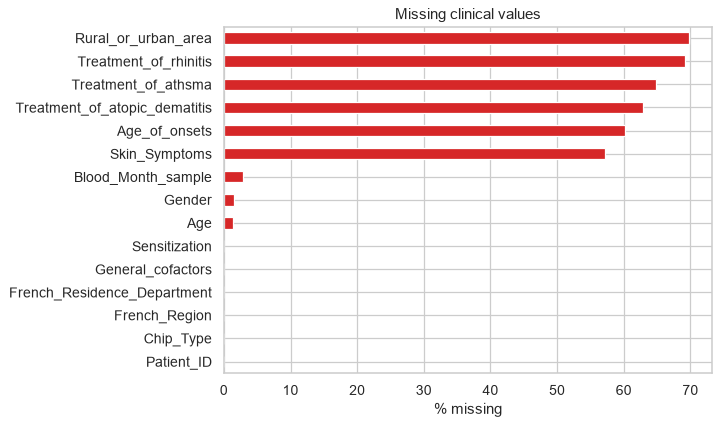

In [4]:
missing = clin.isna().mean().sort_values() * 100

ax = missing.plot.barh(figsize=(7, 5), color="tab:red")
ax.set_xlabel("% missing")
ax.set_title("Missing clinical values")
plt.show()

## 3. Qui sont les patients ?

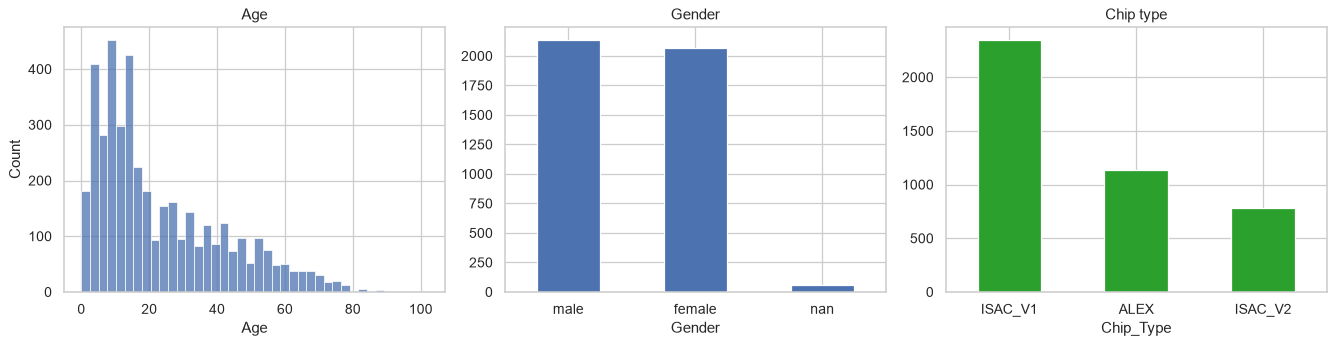

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["Age"], bins=40, ax=axes[0])
axes[0].set_title("Age")

df["Gender"].map({"1": "male", "0": "female"}).value_counts(dropna=False).plot.bar(ax=axes[1])
axes[1].set_title("Gender")

df["Chip_Type"].value_counts().plot.bar(ax=axes[2], color="tab:green")
axes[2].set_title("Chip type")

for ax in axes[1:]:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

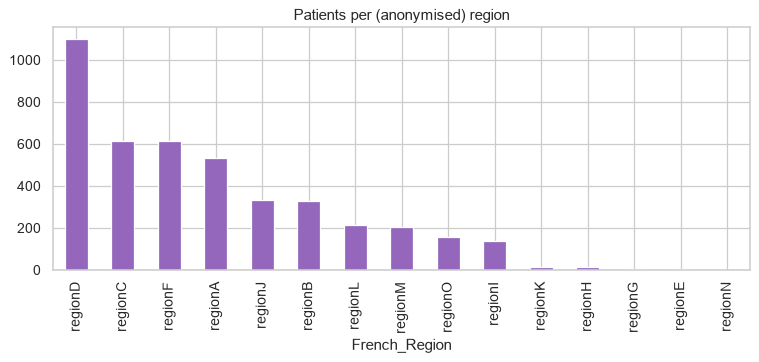

In [6]:
ax = df["French_Region"].value_counts().plot.bar(figsize=(10, 3.5), color="tab:purple")
ax.set_title("Patients per (anonymised) region")
plt.show()

## 4. Le type de puce, une variable centrale

Les trois puces ne mesurent **pas les mêmes allergènes**. Une valeur manquante dans une colonne IgE veut donc souvent dire « allergène absent de cette puce », pas « mesure ratée ».

In [7]:
coverage = df.groupby("Chip_Type")[ige_cols].apply(lambda g: g.notna().mean())
n_measured = (coverage > 0.5).sum(axis=1).rename("allergens measured")
n_measured.to_frame()

,allergens measured
Chip_Type,
ALEX,223
ISAC_V1,112
ISAC_V2,112


In [8]:
shared = coverage.columns[(coverage > 0.5).all()]
print(f"{len(shared)} allergens are measured on all three chips")

91 allergens are measured on all three chips


Les puces n'ont pas non plus été utilisées sur les mêmes patients : comparons l'âge selon la puce.

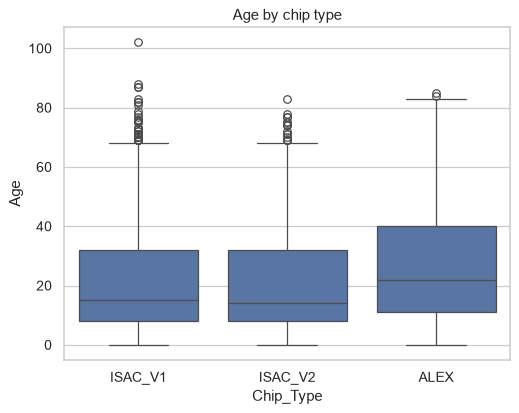

,count,mean,std,min,25%,50%,75%,max
Chip_Type,,,,,,,,
ALEX,1139.0,26.8,19.4,0.0,11.0,22.0,40.0,85.0
ISAC_V1,2351.0,21.7,17.9,0.0,8.0,15.0,32.0,102.0
ISAC_V2,720.0,21.7,18.9,0.0,8.0,14.0,32.0,83.0


In [9]:
ax = sns.boxplot(data=df, x="Chip_Type", y="Age", order=["ISAC_V1", "ISAC_V2", "ALEX"])
ax.set_title("Age by chip type")
plt.show()

df.groupby("Chip_Type")["Age"].describe().round(1)

## 5. Les mesures d'IgE

Chaque colonne IgE contient la concentration d'anticorps contre un allergène (kUA/L pour ALEX, ISU pour ISAC). On regarde d'abord la forme des valeurs.

In [10]:
values = df[ige_cols].stack()  # drops NaN (allergen not on the chip)

print(f"Measured values : {len(values)}")
print(f"Exactly zero    : {(values == 0).mean():.1%}")
print(f"Above 0.3       : {(values >= 0.3).mean():.1%}")

Measured values : 1029311
Exactly zero    : 48.4%
Above 0.3       : 6.1%


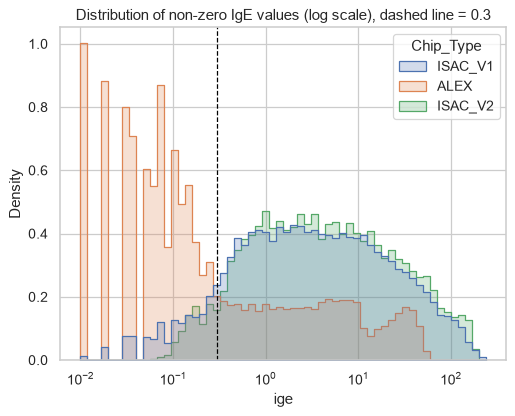

In [11]:
positive = df.melt(id_vars="Chip_Type", value_vars=ige_cols, value_name="ige").query("ige > 0")

ax = sns.histplot(data=positive, x="ige", hue="Chip_Type", log_scale=True,
                  element="step", stat="density", common_norm=False)
ax.axvline(0.3, color="black", ls="--", lw=1)
ax.set_title("Distribution of non-zero IgE values (log scale), dashed line = 0.3")
plt.show()

Deux choses ressortent :
- les valeurs non nulles s'étalent sur **plusieurs ordres de grandeur** : il faudra travailler en échelle log, ou binariser ;
- les puces ne rapportent pas les petites valeurs de la même façon. **ALEX** donne des valeurs entre 0,01 et 0,3, alors que les **ISAC** renvoient 0 sous leur seuil de détection. Les échelles ne sont donc pas directement comparables entre puces.

On utilisera donc plutôt un **seuil de positivité**.

Le seuil usuel est **0,3** (kUA/L pour ALEX, ISU pour ISAC) : au-dessus, le patient est considéré sensibilisé à l'allergène.

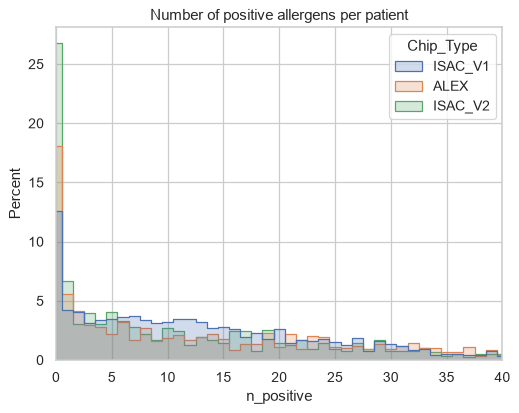

,count,mean,std,min,25%,50%,75%,max
Chip_Type,,,,,,,,
ALEX,1139.0,18.8,21.5,0.0,2.0,12.0,28.5,134.0
ISAC_V1,2351.0,13.8,12.4,0.0,4.0,11.0,21.0,77.0
ISAC_V2,781.0,11.3,13.2,0.0,0.0,6.0,19.0,70.0


In [12]:
THRESHOLD = 0.3

# 1 = positive, 0 = negative, NaN = allergen not on the patient's chip
sensitized = df[ige_cols].ge(THRESHOLD).astype(float).where(df[ige_cols].notna())
df["n_positive"] = sensitized.sum(axis=1)

ax = sns.histplot(data=df, x="n_positive", hue="Chip_Type", discrete=True,
                  stat="percent", common_norm=False, element="step")
ax.set_xlim(0, 40)
ax.set_title("Number of positive allergens per patient")
plt.show()

df.groupby("Chip_Type")["n_positive"].describe().round(1)

### Cohérence avec la variable `Sensitization`

`Sensitization` dit si le patient est sensibilisé à au moins un allergène. On vérifie qu'elle colle au nombre d'allergènes positifs.

In [13]:
pd.crosstab(df["Sensitization"], df["n_positive"].clip(upper=3).astype(int)
            .map({0: "0", 1: "1", 2: "2", 3: "3+"}), margins=True)

n_positive,0,1,2,3+,All
Sensitization,,,,,
0,689,3,0,0,692
1,22,213,167,3177,3579
All,711,216,167,3177,4271


### Les sensibilisations les plus fréquentes

Pour chaque allergène, on calcule la part de patients positifs **parmi ceux pour qui il a été mesuré**.

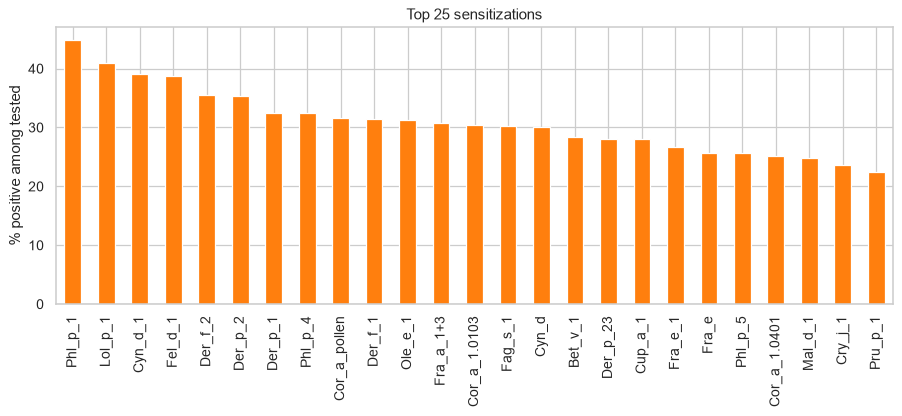

In [14]:
prevalence = sensitized.mean().sort_values(ascending=False) * 100

ax = prevalence.head(25).plot.bar(figsize=(12, 4), color="tab:orange")
ax.set_ylabel("% positive among tested")
ax.set_title("Top 25 sensitizations")
plt.show()

### Co-sensibilisations

Certains allergènes sont souvent positifs ensemble (protéines proches entre espèces, ou même source). La corrélation entre indicateurs de positivité donne une première idée de ces groupes.

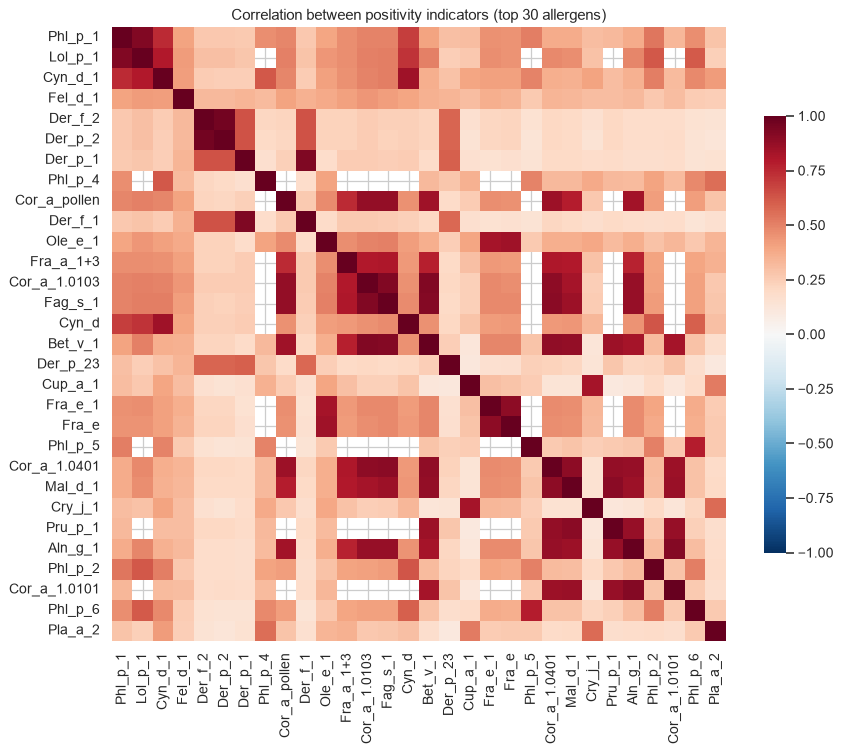

In [15]:
top = prevalence.head(30).index
corr = sensitized[top].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7})
plt.title("Correlation between positivity indicators (top 30 allergens)")
plt.show()

Des blocs bien nets apparaissent :
- **graminées** : `Phl_p_1`, `Lol_p_1`, `Cyn_d_1` ;
- **acariens** : `Der_p_1/2`, `Der_f_1/2`, `Der_p_23` ;
- un gros bloc **PR-10** qui mélange pollens d'arbres (`Bet_v_1`, `Aln_g_1`, `Fag_s_1`, `Cor_a_1`) et aliments (`Mal_d_1` pomme, `Pru_p_1` pêche). C'est la réactivité croisée pollen–aliment (syndrome oral), en général peu sévère.

Les cases blanches correspondent à des paires d'allergènes qui ne sont **jamais mesurées ensemble** (pas sur la même puce).

## 6. Variables cliniques et type de puce

La disponibilité des données cliniques dépend-elle de la puce (donc, indirectement, du centre et de la période) ?

In [16]:
clin.drop(columns=["Patient_ID", "Chip_Type"]).notna().groupby(df["Chip_Type"]).mean().T.mul(100).round(0)

Chip_Type,ALEX,ISAC_V1,ISAC_V2
Age,100.0,100.0,92.0
Gender,100.0,100.0,92.0
Blood_Month_sample,94.0,100.0,92.0
French_Residence_Department,100.0,100.0,100.0
French_Region,100.0,100.0,100.0
Rural_or_urban_area,23.0,24.0,59.0
Sensitization,100.0,100.0,100.0
Treatment_of_rhinitis,30.0,28.0,39.0
Treatment_of_athsma,38.0,30.0,46.0
Age_of_onsets,44.0,28.0,67.0


Distribution des niveaux de traitement de l'asthme et de la rhinite, parmi les patients renseignés :

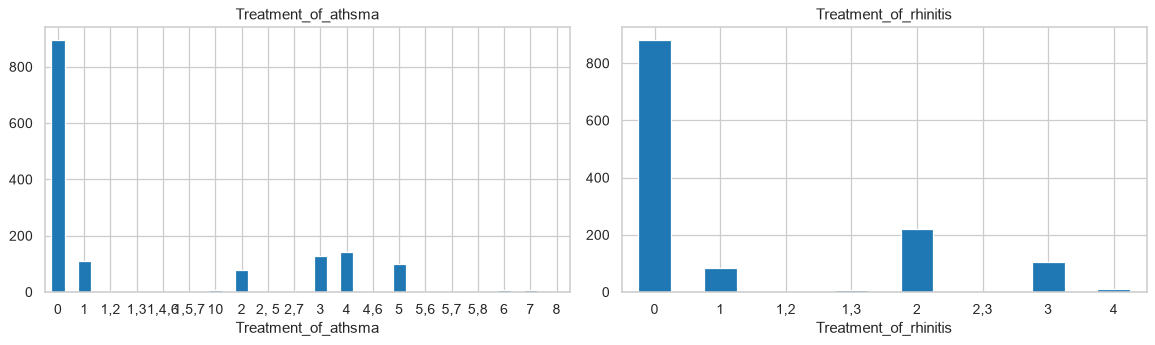

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Treatment_of_athsma", "Treatment_of_rhinitis"]):
    clin[col].value_counts().sort_index().plot.bar(ax=ax, color="tab:blue")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 7. Allergènes et variables cliniques

L'âge, le sexe ou les traitements sont-ils associés à certaines sensibilisations ?

On résume chaque variable clinique en une variable simple :

| Variable | Codage |
|---|---|
| `Age` | âge en années |
| `Male` | 1 = homme, 0 = femme |
| `Urban` | 1 = urbain, 0 = rural |
| `Asthma treated`, `Rhinitis treated`, `Atopic dermatitis treated` | 1 = au moins un traitement, 0 = aucun |
| `Skin symptoms` | 1 = oui, 0 = non |
| `Any cofactor` | 1 = au moins un cofacteur déclaré, 0 = « aucun connu » |

Pour les allergènes, on prend leur **positivité** (IgE ≥ 0,3). On se limite aux allergènes présents sur les trois puces et positifs chez au moins 5 % des patients, pour éviter les estimations sur trop peu de cas.

In [18]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

from acc.allergens import FAMILIES, family_of, sort_by_family


def first_code(col):
    """First code of a (possibly multi-coded) clinical value, NaN if not provided."""
    return pd.to_numeric(clin[col].str.split(",").str[0], errors="coerce")


def treated(col):
    code = first_code(col)
    return (code > 0).astype(float).where(code.notna())


features = pd.DataFrame({
    "Age": df["Age"],
    "Male": pd.to_numeric(df["Gender"]),
    "Urban": first_code("Rural_or_urban_area"),
    "Asthma treated": treated("Treatment_of_athsma"),
    "Rhinitis treated": treated("Treatment_of_rhinitis"),
    "Atopic dermatitis treated": treated("Treatment_of_atopic_dematitis"),
    "Skin symptoms": first_code("Skin_Symptoms"),
    "Any cofactor": treated("General_cofactors"),
})

selected = [c for c in shared if sensitized[c].mean() >= 0.05]
selected = sort_by_family(selected)

features.notna().sum().rename("patients with a value").to_frame().T

,Age,Male,Urban,Asthma treated,Rhinitis treated,Atopic dermatitis treated,Skin symptoms,Any cofactor
patients with a value,4210,4209,1291,1500,1313,1582,1826,4271


**Mesure d'association** : la corrélation de **Spearman**, calculée sur les patients pour qui les deux variables sont connues. Entre deux variables binaires, elle vaut le coefficient φ ; avec l'âge, elle mesure une tendance monotone (la sensibilisation augmente ou diminue avec l'âge).

Avec plusieurs centaines de tests, certains seront « significatifs » par hasard. On corrige donc les p-values pour les **tests multiples** (Benjamini-Hochberg, contrôle du taux de fausses découvertes). Une étoile marque une association qui reste significative après correction (q < 0,05).

In [19]:
rows = []
for feat in features.columns:
    for allergen in selected:
        pair = pd.concat([features[feat], sensitized[allergen]], axis=1).dropna()
        rho, p = spearmanr(pair.iloc[:, 0], pair.iloc[:, 1])
        rows.append({"feature": feat, "allergen": allergen, "rho": rho, "p": p, "n": len(pair)})

assoc = pd.DataFrame(rows)
assoc["q"] = multipletests(assoc["p"], method="fdr_bh")[1]

rho = assoc.pivot(index="feature", columns="allergen", values="rho").loc[features.columns, selected]
q = assoc.pivot(index="feature", columns="allergen", values="q").loc[features.columns, selected]
print(f"{len(assoc)} tests, {(assoc['q'] < 0.05).sum()} significant after FDR correction")

520 tests, 342 significant after FDR correction


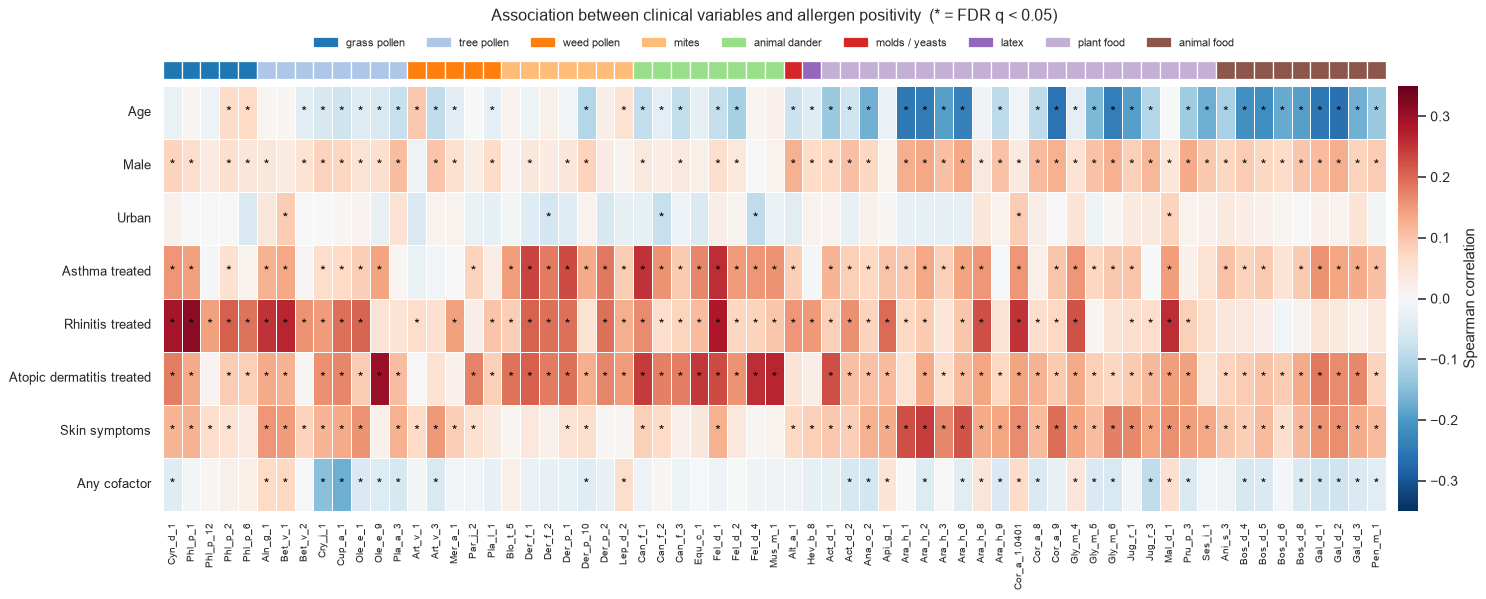

In [20]:
from matplotlib.patches import Patch

family_colors = dict(zip(FAMILIES, sns.color_palette("tab20", len(FAMILIES))))
vmax = np.ceil(rho.abs().max().max() * 20) / 20

fig, axes = plt.subplots(2, 2, figsize=(18, 6.5),
                         gridspec_kw={"height_ratios": [0.35, 8], "width_ratios": [60, 1],
                                      "hspace": 0.03, "wspace": 0.02})
(ax_fam, ax_empty), (ax, ax_cbar) = axes
ax_empty.axis("off")

# family strip above the heatmap, aligned with its columns
ax_fam.bar(np.arange(len(selected)) + 0.5, 1, width=1,
           color=[family_colors[family_of(c)] for c in selected])
ax_fam.set_xlim(0, len(selected))
ax_fam.set_ylim(0, 1)
ax_fam.axis("off")

sns.heatmap(rho, ax=ax, cbar_ax=ax_cbar, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
            annot=np.where(q < 0.05, "*", ""), fmt="", annot_kws={"fontsize": 11, "color": "black"},
            linewidths=0.4, linecolor="white", cbar_kws={"label": "Spearman correlation"})
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=8, rotation=90)
ax.tick_params(axis="y", labelsize=10, rotation=0)

present = [f for f in FAMILIES if any(family_of(c) == f for c in selected)]
ax_fam.legend(handles=[Patch(color=family_colors[f], label=f) for f in present],
              ncol=len(present), loc="lower center", bbox_to_anchor=(0.5, 1.1), frameon=False, fontsize=9)
ax_fam.set_title("Association between clinical variables and allergen positivity  (* = FDR q < 0.05)",
                 pad=32, fontsize=13)
plt.show()

**Lecture de la heatmap**
- **Âge** : corrélation négative avec presque tous les **aliments** (œuf `Gal_d`, lait `Bos_d`, arachide `Ara_h`, soja `Gly_m`, fruits à coque…), et légèrement positive avec certains pollens. Les sensibilisations alimentaires concernent surtout les enfants (voir le zoom ci-dessous).
- **Traitements de l'asthme et de la rhinite, symptômes cutanés** : associations positives avec la plupart des allergènes. Les plus fortes vont dans le sens attendu : la **rhinite** avec les graminées (`Phl_p_1`, `Cyn_d_1`) et le chat (`Fel_d_1`), l'**asthme** avec les acariens et les animaux, les **symptômes cutanés** avec l'arachide (`Ara_h_1/2/6`).
- **Sexe** : les hommes sont un peu plus souvent positifs, pour presque tous les allergènes.
- **Urbain / rural** : quasiment rien, mais seulement 1 291 patients ont cette information.
- **Cofacteurs** : faiblement négatif avec les pollens méditerranéens (`Cup_a_1`, `Ole_e_1`, `Cry_j_1`). C'est probablement un effet centre plutôt qu'un vrai lien biologique.

**Prudence**, car 342 associations sur 520 sont significatives. Deux raisons :
1. **Effet « intensité globale »** : un patient traité ou un garçon est en moyenne plus polysensibilisé, donc positif à *plus d'allergènes en général*. Une colonne entièrement rouge reflète ce niveau global (l'axe PC1 de la PCA), pas un lien spécifique à chaque allergène. Pour isoler les associations propres à un allergène, il faudrait ajuster sur le nombre total d'allergènes positifs.
2. **Grand effectif** : avec plus de 4 000 patients, des corrélations très faibles (|ρ| ≈ 0,05) deviennent significatives. Il faut regarder la **taille** de l'effet (la couleur), pas seulement l'étoile.

Il faut aussi garder en tête les **facteurs de confusion** : l'âge et la disponibilité des traitements varient selon la puce et le centre. Toutes ces associations sont **descriptives**, sans lien de causalité.

### Zoom sur l'âge

Une corrélation ne capture qu'une tendance monotone, alors que la sensibilisation peut monter puis redescendre avec l'âge. On trace donc la **part de patients positifs par tranche d'âge** pour quelques allergènes emblématiques. La zone colorée est l'intervalle de confiance à 95 % (méthode de Wilson), qui s'élargit quand la tranche contient peu de patients.

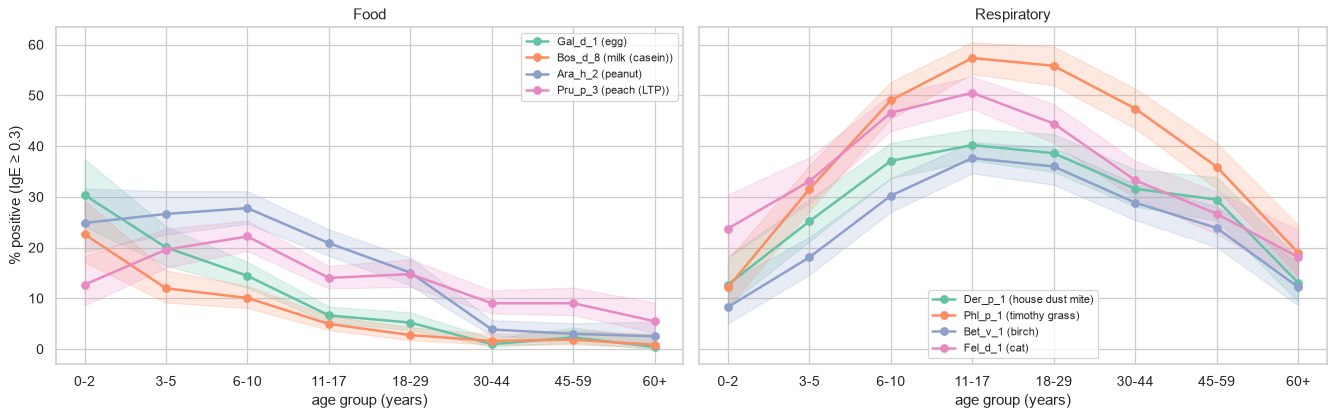

Age,0-2,3-5,6-10,11-17,18-29,30-44,45-59,60+
patients,181,409,734,948,650,620,431,237


In [21]:
from statsmodels.stats.proportion import proportion_confint

AGE_BINS = [0, 3, 6, 11, 18, 30, 45, 60, 110]
AGE_LABELS = ["0-2", "3-5", "6-10", "11-17", "18-29", "30-44", "45-59", "60+"]
age_group = pd.cut(df["Age"], bins=AGE_BINS, labels=AGE_LABELS, right=False)

PANELS = {
    "Food": {"Gal_d_1": "egg", "Bos_d_8": "milk (casein)", "Ara_h_2": "peanut",
             "Pru_p_3": "peach (LTP)"},
    "Respiratory": {"Der_p_1": "house dust mite", "Phl_p_1": "timothy grass",
                    "Bet_v_1": "birch", "Fel_d_1": "cat"},
}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, (title, allergens) in zip(axes, PANELS.items()):
    for (allergen, label), color in zip(allergens.items(), sns.color_palette("Set2", 4)):
        grouped = sensitized[allergen].groupby(age_group, observed=False)
        k, n = grouped.sum(), grouped.count()
        low, high = proportion_confint(k, n, method="wilson")
        x = np.arange(len(AGE_LABELS))
        ax.plot(x, 100 * k / n, marker="o", color=color, lw=2, label=f"{allergen} ({label})")
        ax.fill_between(x, 100 * low, 100 * high, color=color, alpha=0.2)
    ax.set_xticks(np.arange(len(AGE_LABELS)))
    ax.set_xticklabels(AGE_LABELS)
    ax.set_xlabel("age group (years)")
    ax.set_title(title)
    ax.legend(fontsize=9)
axes[0].set_ylabel("% positive (IgE ≥ 0.3)")
plt.tight_layout()
plt.show()

age_group.value_counts().reindex(AGE_LABELS).rename("patients").to_frame().T

Le profil par âge est très net, et c'est la **« marche atopique »** décrite en allergologie :
- les sensibilisations **alimentaires** sont maximales dans la petite enfance. L'œuf et le lait passent d'environ 25 à 30 % avant 3 ans à presque 0 après 30 ans. L'arachide reste élevée jusque vers 10 ans ;
- les sensibilisations **respiratoires** montent pendant l'enfance, culminent à l'**adolescence** (11 à 17 ans, jusqu'à 57 % pour les graminées), puis redescendent.

Attention, ce sont des données **transversales** : chaque tranche contient des patients différents, il ne s'agit pas du suivi des mêmes personnes. Et le recrutement hospitalier ne dépend pas forcément de l'âge de la même façon (on consulte pour des raisons différentes à 2 ans et à 50 ans).

## 8. Ce qu'on retient

**Population**
- Population plutôt **jeune** : âge médian autour de 15 ans, avec beaucoup d'enfants. Les patients ALEX sont un peu plus âgés (médiane 22 ans contre 15).
- Sexe équilibré.
- 84 % des patients sont sensibilisés à au moins un allergène (`Sensitization = 1`). C'est cohérent avec le décompte des IgE ≥ 0,3, à quelques dizaines de patients près.

**Données cliniques**
- Les variables les plus intéressantes pour la sévérité (traitements, symptômes cutanés, âge d'apparition) manquent pour **57 à 70 %** des patients.
- Ce taux dépend de la puce, donc probablement du centre : les patients ISAC v2 sont bien mieux renseignés.
- `General_cofactors` semble complète, mais son code `0` signifie « aucun **connu** » : le manque d'information y est probablement caché.

**IgE**
- Trois puces, trois listes d'allergènes : 112 pour ISAC, 223 pour ALEX, seulement **91 en commun**.
- Les échelles diffèrent aussi : ALEX rapporte des valeurs sous 0,3, alors qu'ISAC met 0.
- Il faudra donc toujours tenir compte de `Chip_Type`, ou se restreindre aux allergènes communs avec un seuil de positivité.
- Les sensibilisations les plus fréquentes sont **respiratoires** : graminées, acariens, chat, pollens d'arbres. Les marqueurs alimentaires sévères (`Ara_h_2`, `Pru_p_3`, `Cor_a_14`…) touchent environ 10 à 16 % des patients.
- Les co-sensibilisations forment des familles cohérentes (graminées, acariens, PR-10). Regrouper les allergènes par **famille de protéines** est une piste naturelle pour la suite.

**Clinique × allergènes**
- L'âge structure fortement les sensibilisations : les aliments dominent dans la petite enfance, les allergènes respiratoires culminent à l'adolescence.
- Les traitements et symptômes sont associés à presque tous les allergènes. C'est surtout un effet du niveau global de sensibilisation : il faudra ajuster dessus pour trouver des associations propres à certains allergènes.

**Pistes pour la suite**
1. Construire une table « propre » partagée : `9` → NaN, codes multiples → indicatrices, IgE binarisées par puce.
2. Définir un ou plusieurs proxys de sévérité à partir des traitements de l'asthme et de la rhinite.
3. Clustering ou ACP sur les 91 allergènes communs, en vérifiant que les clusters ne reflètent pas simplement le type de puce.